In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from pathlib import Path

file_path = Path.home() / "Desktop" / "Project Data Analysis" / "main.csv"

df = pd.read_csv(file_path, low_memory=False)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Number of rows: 1159430
Number of columns: 23

Column names:
['Unnamed: 0', 'Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Consumer consent provided?', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Consumer disputed?', 'Complaint ID', 'Year', 'Month', 'Day', 'DoW']


,Unnamed: 0,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,...,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID,Year,Month,Day,DoW
0,6,2022-12-24,Checking or savings account,Checking account,Managing an account,Deposits and withdrawals,I opened up a account online XXXX weeks ago an...,Company has responded to the consumer and the ...,BMO HARRIS BANK NATIONAL ASSOCIATION,AZ,...,Web,2022-12-24,Closed with explanation,Yes,NaN,6358144,2022,12,24,5
1,8,2022-12-20,Credit card or prepaid card,General-purpose credit card or charge card,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,Received credit card statement dated XX/XX/22 ...,Company has responded to the consumer and the ...,U.S. BANCORP,OH,...,Web,2022-12-20,Closed with non-monetary relief,Yes,NaN,6338237,2022,12,20,1
2,10,2022-12-16,Credit card or prepaid card,Store credit card,Fees or interest,Unexpected increase in interest rate,When signing up with the card they never tell ...,Company has responded to the consumer and the ...,SYNCHRONY FINANCIAL,NY,...,Web,2022-12-16,Closed with explanation,Yes,NaN,6329064,2022,12,16,4
3,15,2022-12-16,"Credit reporting, credit repair services, or o...",Credit reporting,Problem with a credit reporting company's inve...,Their investigation did not fix an error on yo...,I reviewed my Consumer Reports and noticed tha...,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,CA,...,Web,2022-12-16,Closed with explanation,Yes,NaN,6323220,2022,12,16,4
4,22,2022-12-05,Debt collection,Medical debt,Attempts to collect debt not owed,Debt is not yours,"I had a ER visit on XX/XX/2020, at the time i ...",Company has responded to the consumer and the ...,"PlusFour, Inc",NV,...,Web,2022-12-29,Closed with explanation,Yes,NaN,6282728,2022,12,5,0


In [3]:
text_col = "Consumer complaint narrative"

missing_text = df[text_col].isna().sum()
empty_text = df[text_col].fillna("").str.strip().eq("").sum()
duplicate_rows = df.duplicated().sum()

valid_text = df[text_col].dropna().astype(str).str.strip()
valid_text = valid_text[valid_text != ""]
duplicate_texts = valid_text.duplicated().sum()

print("Total rows:", len(df))
print("Missing complaint texts:", missing_text)
print("Empty complaint texts:", empty_text)
print("Duplicate complete rows:", duplicate_rows)
print("Repeated non-empty complaint texts:", duplicate_texts)

print("\nDate range:")
print(df["Date received"].min(), "to", df["Date received"].max())

print("\nNumber of product categories:")
print(df["Product"].nunique())

Total rows: 1159430
Missing complaint texts: 0
Empty complaint texts: 0
Duplicate complete rows: 0
Repeated non-empty complaint texts: 150118

Date range:
2015-03-19 to 2022-12-30

Number of product categories:
18


In [5]:
complaints = df.dropna(subset=[text_col]).copy()

complaints = complaints[
    complaints[text_col].astype(str).str.strip() != ""
]

print("Rows with actual complaint text:", len(complaints))

sample_df = complaints.sample(
    n=min(3000, len(complaints)),
    random_state=42
).copy()

print("Number of complaints selected:", len(sample_df))

display(sample_df[[text_col, "Product"]].head())

Rows with actual complaint text: 1159430
Number of complaints selected: 3000


,Consumer complaint narrative,Product
217644,They never respond to me and continually repor...,"Credit reporting, credit repair services, or o..."
18180,My name is XXXX XXXX this complaint is not mad...,"Credit reporting, credit repair services, or o..."
1000420,I recently checked my credit report and notice...,"Credit reporting, credit repair services, or o..."
982851,I already submitted CFPB complaints for both X...,"Credit reporting, credit repair services, or o..."
1008014,I have been trying to close my mother 's accou...,Checking or savings account


# Initial Analysis (Before Improved Cleaning)

In [7]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

sample_df["clean_text"] = sample_df[text_col].apply(clean_text)

display(sample_df[[text_col, "clean_text"]].head())

,Consumer complaint narrative,clean_text
217644,They never respond to me and continually repor...,they never respond to me and continually repor...
18180,My name is XXXX XXXX this complaint is not mad...,my name is xxxx xxxx this complaint is not mad...
1000420,I recently checked my credit report and notice...,i recently checked my credit report and notice...
982851,I already submitted CFPB complaints for both X...,i already submitted cfpb complaints for both x...
1008014,I have been trying to close my mother 's accou...,i have been trying to close my mother s accoun...


In [9]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = sample_df["clean_text"].tolist()

# Bag-of-Words
count_vectorizer = CountVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=2,
    max_df=0.95
)

bow_matrix = count_vectorizer.fit_transform(texts)

# TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=2,
    max_df=0.95
)

tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("Bag-of-Words matrix:", bow_matrix.shape)
print("TF-IDF matrix:", tfidf_matrix.shape)

Bag-of-Words matrix: (3000, 5000)
TF-IDF matrix: (3000, 5000)


In [12]:
from gensim import corpora
from gensim.models import LdaModel

# Split each cleaned complaint into words
tokenized_texts = [
    text.split() for text in sample_df["clean_text"]
]

# Create a dictionary and corpus for Gensim
dictionary = corpora.Dictionary(tokenized_texts)

dictionary.filter_extremes(
    no_below=2,
    no_above=0.95
)

corpus = [
    dictionary.doc2bow(text)
    for text in tokenized_texts
]

# Train the LDA model
lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=5,
    random_state=42,
    passes=5,
    iterations=50
)

# Display the main words for each topic
for topic_id, words in lda_model.print_topics(num_words=10):
    print(f"Topic {topic_id + 1}: {words}")

Topic 1: 0.061*"the" + 0.040*"to" + 0.034*"of" + 0.025*"and" + 0.024*"a" + 0.017*"i" + 0.016*"in" + 0.015*"that" + 0.014*"xxxx" + 0.013*"this"
Topic 2: 0.047*"i" + 0.043*"the" + 0.040*"to" + 0.034*"and" + 0.024*"my" + 0.019*"a" + 0.018*"that" + 0.017*"was" + 0.016*"they" + 0.014*"me"
Topic 3: 0.205*"xxxx" + 0.028*"the" + 0.024*"my" + 0.024*"a" + 0.020*"to" + 0.018*"credit" + 0.017*"of" + 0.016*"and" + 0.016*"i" + 0.016*"account"
Topic 4: 0.097*"xxxx" + 0.046*"i" + 0.044*"xx" + 0.028*"the" + 0.026*"and" + 0.026*"to" + 0.021*"my" + 0.018*"a" + 0.017*"on" + 0.016*"this"
Topic 5: 0.055*"my" + 0.042*"i" + 0.034*"credit" + 0.028*"and" + 0.027*"to" + 0.027*"accounts" + 0.025*"have" + 0.020*"that" + 0.017*"these" + 0.016*"report"


In [14]:
from sklearn.decomposition import TruncatedSVD

lsa_model = TruncatedSVD(
    n_components=5,
    random_state=42
)

lsa_model.fit(tfidf_matrix)

feature_names = tfidf_vectorizer.get_feature_names_out()

for topic_id, component in enumerate(lsa_model.components_):
    top_indices = component.argsort()[-10:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_id + 1}: {', '.join(top_words)}")

Topic 1: xxxx, xx, credit, account, report, reporting, information, debt, section, accounts
Topic 2: xxxx, xxxxxxxx, ca, oh, fl, tx, mo, ga, nj, nc
Topic 3: xx, loan, payment, received, bank, told, payments, company, mortgage, called
Topic 4: xx, section, states, privacy, furnish, instructions, violated, accordance, rights, written
Topic 5: xx, report, accounts, information, inaccurate, theft, items, identity, credit, consumer


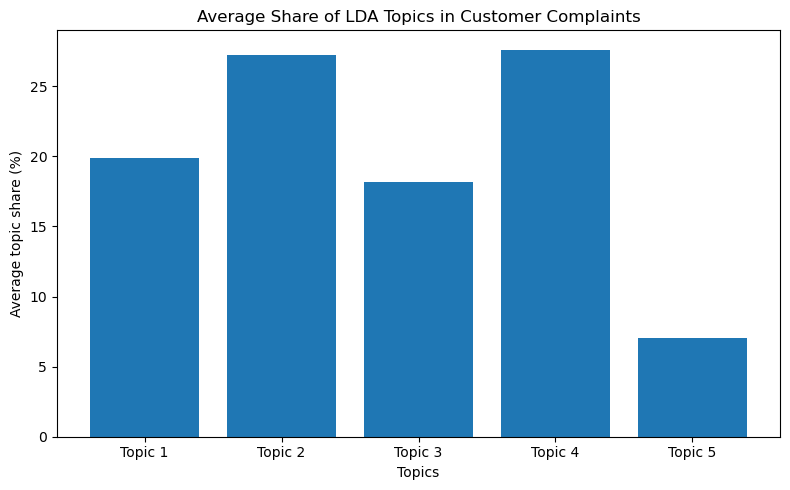

Average LDA topic shares:
Topic 1: 19.91%
Topic 2: 27.23%
Topic 3: 18.19%
Topic 4: 27.60%
Topic 5: 7.07%


In [16]:
topic_totals = np.zeros(5)

for document in corpus:
    topic_distribution = lda_model.get_document_topics(
        document,
        minimum_probability=0
    )

    for topic_id, probability in topic_distribution:
        topic_totals[topic_id] += probability

topic_shares = topic_totals / len(corpus) * 100

plt.figure(figsize=(8, 5))
plt.bar(
    [f"Topic {i+1}" for i in range(5)],
    topic_shares
)

plt.title("Average Share of LDA Topics in Customer Complaints")
plt.xlabel("Topics")
plt.ylabel("Average topic share (%)")
plt.tight_layout()
plt.show()

print("Average LDA topic shares:")
for i, share in enumerate(topic_shares):
    print(f"Topic {i+1}: {share:.2f}%")

In [20]:
sample_df.to_csv(
    "banking_complaints_sample_3000.csv",
    index=False
)

# Final Analysis (After Improved Cleaning)

In [23]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"\b(?:x+)\b", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)

    words = text.split()
    words = [word for word in words if word not in ENGLISH_STOP_WORDS]

    return " ".join(words)

sample_df["clean_text"] = sample_df[text_col].apply(clean_text)

display(sample_df[[text_col, "clean_text"]].head())

,Consumer complaint narrative,clean_text
217644,They never respond to me and continually repor...,respond continually report wrong information r...
18180,My name is XXXX XXXX this complaint is not mad...,complaint error party declare penalty perjury ...
1000420,I recently checked my credit report and notice...,recently checked credit report noticed fraudul...
982851,I already submitted CFPB complaints for both X...,submitted cfpb complaints related mortgage att...
1008014,I have been trying to close my mother 's accou...,trying close mother s account bank america die...


In [25]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = sample_df["clean_text"].tolist()

# Bag-of-Words
count_vectorizer = CountVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=2,
    max_df=0.95
)

bow_matrix = count_vectorizer.fit_transform(texts)

# TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=2,
    max_df=0.95
)

tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("Bag-of-Words matrix:", bow_matrix.shape)
print("TF-IDF matrix:", tfidf_matrix.shape)

Bag-of-Words matrix: (3000, 5000)
TF-IDF matrix: (3000, 5000)


In [27]:
from gensim import corpora
from gensim.models import LdaModel

# Split each cleaned complaint into words
tokenized_texts = [
    text.split() for text in sample_df["clean_text"]
]

# Create a dictionary and corpus for Gensim
dictionary = corpora.Dictionary(tokenized_texts)

dictionary.filter_extremes(
    no_below=2,
    no_above=0.95
)

corpus = [
    dictionary.doc2bow(text)
    for text in tokenized_texts
]

# Train the LDA model
lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=5,
    random_state=42,
    passes=5,
    iterations=50
)

# Display the main words for each topic
for topic_id, words in lda_model.print_topics(num_words=10):
    print(f"Topic {topic_id + 1}: {words}")

Topic 1: 0.015*"loan" + 0.013*"payments" + 0.012*"account" + 0.012*"payment" + 0.009*"credit" + 0.007*"loans" + 0.006*"received" + 0.006*"time" + 0.006*"claim" + 0.005*"s"
Topic 2: 0.019*"account" + 0.012*"bank" + 0.012*"payment" + 0.012*"told" + 0.009*"loan" + 0.009*"card" + 0.009*"called" + 0.008*"t" + 0.008*"credit" + 0.008*"received"
Topic 3: 0.065*"credit" + 0.035*"report" + 0.025*"account" + 0.023*"information" + 0.017*"accounts" + 0.015*"reporting" + 0.010*"removed" + 0.009*"bureaus" + 0.009*"reported" + 0.009*"letter"
Topic 4: 0.038*"debt" + 0.016*"credit" + 0.011*"information" + 0.010*"consumer" + 0.010*"reporting" + 0.009*"collection" + 0.009*"report" + 0.008*"company" + 0.008*"n" + 0.008*"alleged"
Topic 5: 0.047*"consumer" + 0.031*"account" + 0.031*"reporting" + 0.030*"information" + 0.026*"section" + 0.022*"s" + 0.022*"credit" + 0.018*"c" + 0.018*"agency" + 0.017*"u"


In [29]:
from sklearn.decomposition import TruncatedSVD

lsa_model = TruncatedSVD(
    n_components=5,
    random_state=42
)

lsa_model.fit(tfidf_matrix)

feature_names = tfidf_vectorizer.get_feature_names_out()

for topic_id, component in enumerate(lsa_model.components_):
    top_indices = component.argsort()[-10:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_id + 1}: {', '.join(top_words)}")

Topic 1: credit, account, report, reporting, section, information, consumer, accounts, states, debt
Topic 2: section, states, consumer, furnish, privacy, reporting, instructions, violated, rights, accordance
Topic 3: report, accounts, credit, information, identity, theft, items, inaccurate, remove, bureaus
Topic 4: debt, collection, company, consumer, alleged, validation, collect, collector, owe, information
Topic 5: account, debt, collection, opened, closed, theft, bank, identity, balance, fraudulent


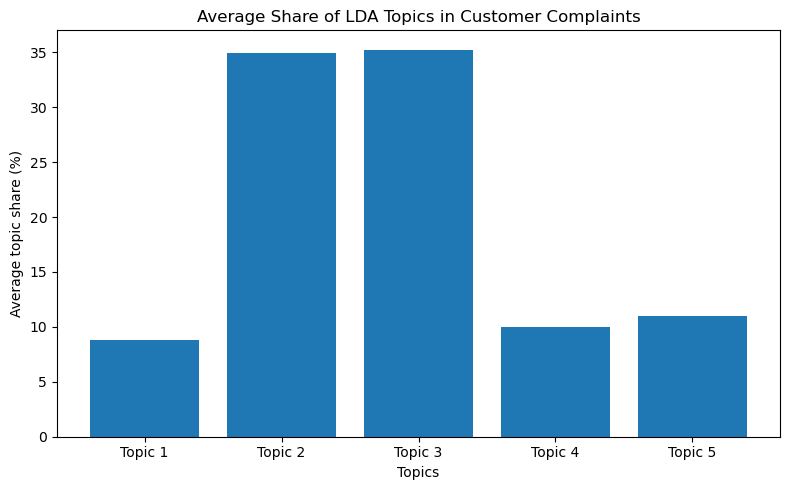

Average LDA topic shares:
Topic 1: 8.85%
Topic 2: 34.92%
Topic 3: 35.23%
Topic 4: 10.01%
Topic 5: 10.99%


In [31]:
topic_totals = np.zeros(5)

for document in corpus:
    topic_distribution = lda_model.get_document_topics(
        document,
        minimum_probability=0
    )

    for topic_id, probability in topic_distribution:
        topic_totals[topic_id] += probability

topic_shares = topic_totals / len(corpus) * 100

plt.figure(figsize=(8, 5))
plt.bar(
    [f"Topic {i+1}" for i in range(5)],
    topic_shares
)

plt.title("Average Share of LDA Topics in Customer Complaints")
plt.xlabel("Topics")
plt.ylabel("Average topic share (%)")
plt.tight_layout()
plt.show()

print("Average LDA topic shares:")
for i, share in enumerate(topic_shares):
    print(f"Topic {i+1}: {share:.2f}%")